In [10]:
import numpy as np
import matplotlib.pyplot as plt

from mp1lib import bsc

SEED = 19 
rng = np.random.default_rng(SEED)
rng_step1 = rng.spawn(1)[0]

test_rng = rng.spawn(1)[0]

test_bits = np.array([0, 1, 1, 0])
test_result = bsc(test_bits, p=0, rng=test_rng)

assert np.array_equal(test_result, test_bits)

print("Setup completed.")
print("bsc test passed.")

Setup completed.
bsc test passed.


## Step 1: The Sample Space and Probability Axioms

For a four-bit packet, each bit has two possible error states:

- $0$: the bit is correct
- $1$: the bit is corrupted

Therefore, the total number of possible error patterns is

$$
2^4 = 16
$$

If a pattern contains $k$ errors, it contains $4-k$ correct bits.
Since the bit errors are independent, the exact probability of that
pattern is

$$
P(\text{pattern}) = p^k(1-p)^{4-k}
$$

where $p=0.1$.

In [11]:
#1) Enumerate all 16 patterns and confirm the sum is 1
p = 0.1

# Generate the numbers 0 through 15
pattern_numbers = np.arange(16)

# Convert each number into a four-bit binary error pattern
patterns = (
    (pattern_numbers[:, None] >> np.arange(3, -1, -1)) & 1
)

# Count the number of errors in each pattern
error_counts = patterns.sum(axis=1)

# Calculate the exact probability of each pattern
exact_pattern_prob = (
    p**error_counts
    * (1 - p)**(4 - error_counts)
)

print(f"{'Pattern':<10} {'Errors':<10} {'Probability':<15}")
print("-" * 35)

for pattern, errors, probability in zip(
    patterns,
    error_counts,
    exact_pattern_prob
):
    pattern_text = "".join(str(bit) for bit in pattern)

    print(
        f"{pattern_text:<10}"
        f"{errors:<10}"
        f"{probability:<15.6f}"
    )

print("-" * 35)
print(f"Sum = {exact_pattern_prob.sum():.10f}")

Pattern    Errors     Probability    
-----------------------------------
0000      0         0.656100       
0001      1         0.072900       
0010      1         0.072900       
0011      2         0.008100       
0100      1         0.072900       
0101      2         0.008100       
0110      2         0.008100       
0111      3         0.000900       
1000      1         0.072900       
1001      2         0.008100       
1010      2         0.008100       
1011      3         0.000900       
1100      2         0.008100       
1101      3         0.000900       
1110      3         0.000900       
1111      4         0.000100       
-----------------------------------
Sum = 1.0000000000


####2) Compute by Hand


The events are:

- $A$: at least one error among the first two bits
- $B$: exactly two errors in the four-bit packet
- $C$: the fourth bit is in error

#### Event A

Event $A$ does not occur when both of the first two bits are correct.
The probability that both are correct is

$$
P(A^c)=(0.9)(0.9)=0.81
$$

Therefore,

$$
P(A)=1-P(A^c)
$$

$$
P(A)=1-0.81=0.19
$$

#### Event B

Event $B$ requires exactly two errors among four bits. The number of
ways to select two error positions from four positions is

$$
\binom{4}{2}=6
$$

Therefore,

$$
P(B)=\binom{4}{2}(0.1)^2(0.9)^2
$$

$$
P(B)=6(0.01)(0.81)=0.0486
$$

#### Event C

Event $C$ occurs when the fourth bit is corrupted. Every individual
bit has an error probability of $0.1$. Therefore,

$$
P(C)=0.1
$$

In [12]:
# A: at least one of the first two bits has an error
A_exact = (patterns[:, 0] == 1) | (patterns[:, 1] == 1)

# B: exactly two errors in the four-bit packet
B_exact = error_counts == 2

# C: the fourth bit has an error
C_exact = patterns[:, 3] == 1

# Add the probabilities of the patterns belonging to each event
P_A = exact_pattern_prob[A_exact].sum()
P_B = exact_pattern_prob[B_exact].sum()
P_C = exact_pattern_prob[C_exact].sum()

print(f"P(A) = {P_A:.4f}")
print(f"P(B) = {P_B:.4f}")
print(f"P(C) = {P_C:.4f}")

P(A) = 0.1900
P(B) = 0.0486
P(C) = 0.1000


In [13]:
#3) Estimate using monte carlo simulations with N^16 packets

N = 1_000_000

# create one million transmitted packets containing four correct bits
transmitted_bits = np.zeros((N, 4), dtype=np.uint8)

# pass all packets through the binary symmetric channel
simulated_patterns = bsc(
    transmitted_bits,
    p=0.1,
    rng=rng_step1
)

# Count the number of errors in each packet
simulated_error_counts = simulated_patterns.sum(axis=1)

# define the simulated events
A_sim = (
    (simulated_patterns[:, 0] == 1)
    | (simulated_patterns[:, 1] == 1)
)

B_sim = simulated_error_counts == 2

C_sim = simulated_patterns[:, 3] == 1

# estimate each probability
P_A_mc = A_sim.mean()
P_B_mc = B_sim.mean()
P_C_mc = C_sim.mean()

print(f"P(A): exact = {P_A:.6f}, mc_estimate = {P_A_mc:.6f}")
print(f"P(B): exact = {P_B:.6f}, mc_estimate = {P_B_mc:.6f}")
print(f"P(C): exact = {P_C:.6f}, mc_estimate = {P_C_mc:.6f}")

P(A): exact = 0.190000, mc_estimate = 0.189813
P(B): exact = 0.048600, mc_estimate = 0.048407
P(C): exact = 0.100000, mc_estimate = 0.099706


#Exact Intersection

The symbol $\cap$ means “and.”

For $A\cap B$, there are five valid patterns with exactly two errors:

$$
P(A\cap B)=5(0.1)^2(0.9)^2=0.0405.
$$

Because $A$ concerns the first two bits and $C$ concerns the fourth bit,

$$
P(A\cap C)=P(A)P(C)=(0.19)(0.1)=0.0190.
$$

For $B\cap C$, the fourth bit is an error and one of the first three
bits is an error:

$$
P(B\cap C)=3(0.1)^2(0.9)^2=0.0243.
$$

For $A\cap B\cap C$, the fourth bit is an error and the other error
must be in bit 1 or bit 2:

$$
P(A\cap B\cap C)=2(0.1)^2(0.9)^2=0.0162.
$$

In [14]:
#4) Compute the three pairwise intersections and the triple intersections, exactly and empirically
P_AB = exact_pattern_prob[A_exact & B_exact].sum()
P_AC = exact_pattern_prob[A_exact & C_exact].sum()
P_BC = exact_pattern_prob[B_exact & C_exact].sum()
P_ABC = exact_pattern_prob[A_exact & B_exact & C_exact].sum()

# Monte Carlo estimates
P_AB_mc = (A_sim & B_sim).mean()
P_AC_mc = (A_sim & C_sim).mean()
P_BC_mc = (B_sim & C_sim).mean()
P_ABC_mc = (A_sim & B_sim & C_sim).mean()

print(f"P(A and B): exact = {P_AB:.6f}, mc_estimate = {P_AB_mc:.6f}")
print(f"P(A and C): exact = {P_AC:.6f}, mc_estimate = {P_AC_mc:.6f}")
print(f"P(B and C): exact = {P_BC:.6f}, mc_estimate = {P_BC_mc:.6f}")
print(f"P(A, B, and C): exact = {P_ABC:.6f}, mc_estimate = {P_ABC_mc:.6f}")

P(A and B): exact = 0.040500, mc_estimate = 0.040334
P(A and C): exact = 0.019000, mc_estimate = 0.019070
P(B and C): exact = 0.024300, mc_estimate = 0.024290
P(A, B, and C): exact = 0.016200, mc_estimate = 0.016217


In [15]:
### 5)Inclusion-Exclusion

# Exact union using inclusion-exclusion
P_union = (
    P_A
    + P_B
    + P_C
    - P_AB
    - P_AC
    - P_BC
    + P_ABC
)
# Monte Carlo estimate calculated directly
P_union_mc = (A_sim | B_sim | C_sim).mean()

print(f"Exact P(A or B or C) = {P_union:.6f}")
print(f"MC estimate           = {P_union_mc:.6f}")
print(f"Absolute difference   = {abs(P_union_mc - P_union):.6e}")

Exact P(A or B or C) = 0.271000
MC estimate           = 0.270449
Absolute difference   = 5.510000e-04


**6) Standard error**

We estimate each event probability using N = 1,000,000
simulated packets.

Standard error measures the typical size of fluctuations
in an estimated probability across repeated simulations.
Using each event's exact probability, we calculate:

$$
\mathrm{SE}
= \sqrt{\frac{P_{\mathrm{exact}}(1-P_{\mathrm{exact}})}{N}}.
$$

We check whether the absolute difference between the
simulation estimate and the exact probability satisfies:

$$
|P_{\mathrm{MC}} - P_{\mathrm{exact}}| \leq 3\,\mathrm{SE}.
$$

For event C, the standard error is 0.0003, so three standard
errors equal 0.0009. Its observed difference is 0.000294,
which is smaller than 0.0009. Therefore, the check passes.

All seven event estimates and the union estimate pass
this check in the current run.

In [16]:
#6)State the standard error of a probability estimate at N = 10^6 
#and confirm every difference above sits within three standard errors. 

event_names = [
    "A",
    "B",
    "C",
    "A and B",
    "A and C",
    "B and C",
    "A and B and C"
]

exact_values = np.array([
    P_A,
    P_B,
    P_C,
    P_AB,
    P_AC,
    P_BC,
    P_ABC
])

mc_values = np.array([
    P_A_mc,
    P_B_mc,
    P_C_mc,
    P_AB_mc,
    P_AC_mc,
    P_BC_mc,
    P_ABC_mc
])

differences = np.abs(mc_values - exact_values)

standard_errors = np.sqrt(
    exact_values * (1 - exact_values) / N
)

within_three_se = differences <= 3 * standard_errors

print(
    f"{'Event':<16}"
    f"{'Exact':>12}"
    f"{'MC estimate':>15}"
    f"{'Difference':>15}"
    f"{'Std. error':>15}"
    f"{'Within 3 SE':>15}"
)

print("-" * 88)

for name, exact, mc, difference, se, within in zip(
    event_names,
    exact_values,
    mc_values,
    differences,
    standard_errors,
    within_three_se
):
    print(
        f"{name:<16}"
        f"{exact:>12.6f}"
        f"{mc:>15.6f}"
        f"{difference:>15.6e}"
        f"{se:>15.6e}"
        f"{str(within):>15}"
    )

Event                  Exact    MC estimate     Difference     Std. error    Within 3 SE
----------------------------------------------------------------------------------------
A                   0.190000       0.189813   1.870000e-04   3.923009e-04           True
B                   0.048600       0.048407   1.930000e-04   2.150303e-04           True
C                   0.100000       0.099706   2.940000e-04   3.000000e-04           True
A and B             0.040500       0.040334   1.660000e-04   1.971288e-04           True
A and C             0.019000       0.019070   7.000000e-05   1.365247e-04           True
B and C             0.024300       0.024290   1.000000e-05   1.539789e-04           True
A and B and C       0.016200       0.016217   1.700000e-05   1.262440e-04           True


In [17]:
#Union

union_difference = abs(P_union_mc - P_union)

union_se = np.sqrt(
    P_union * (1 - P_union) / N
)

union_within_three_se = union_difference <= 3 * union_se

print(f"Union exact:             {P_union:.6f}")
print(f"Union MC estimate:       {P_union_mc:.6f}")
print(f"Union difference:        {union_difference:.6e}")
print(f"Union standard error:    {union_se:.6e}")
print(f"Three standard errors:   {3 * union_se:.6e}")
print(f"Union within three SE:   {union_within_three_se}")

Union exact:             0.271000
Union MC estimate:       0.270449
Union difference:        5.510000e-04
Union standard error:    4.444761e-04
Three standard errors:   1.333428e-03
Union within three SE:   True


All seven event estimates and the union estimate were within three standard errors of their exact probabilities. These results are consistent with the theoretical model and expected sampling variation.

## Figure 1 Plot

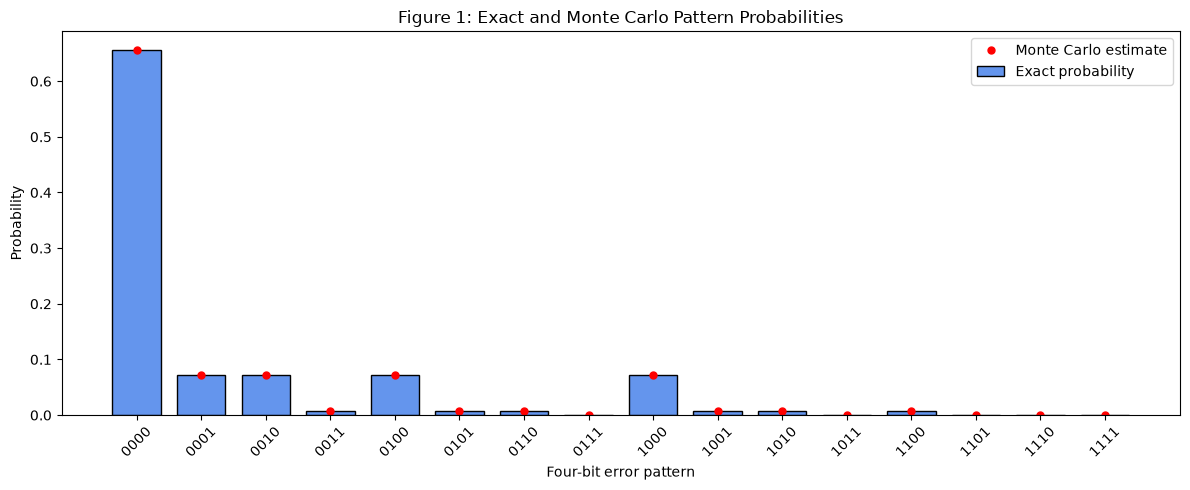

In [18]:
# Convert each simulated four-bit pattern into a number from 0 to 15
binary_weights = np.array([8, 4, 2, 1])

simulated_pattern_numbers = (
    simulated_patterns @ binary_weights
)

# Count how many times each pattern appeared
simulated_pattern_counts = np.bincount(
    simulated_pattern_numbers,
    minlength=16
)

# Convert counts into Monte Carlo probability estimates
mc_pattern_prob = simulated_pattern_counts / N

# Create labels: 0000, 0001, ..., 1111
pattern_labels = [
    "".join(str(bit) for bit in pattern)
    for pattern in patterns
]

x = np.arange(16)

plt.figure(figsize=(12, 5))

# Exact probabilities as bars
plt.bar(
    x,
    exact_pattern_prob,
    width=0.75,
    color="cornflowerblue",
    edgecolor="black",
    label="Exact probability"
)

# Monte Carlo estimates as red dots
plt.plot(
    x,
    mc_pattern_prob,
    "ro",
    markersize=5,
    label="Monte Carlo estimate"
)

plt.xticks(x, pattern_labels, rotation=45)
plt.xlabel("Four-bit error pattern")
plt.ylabel("Probability")
plt.title("Figure 1: Exact and Monte Carlo Pattern Probabilities")
plt.legend()
plt.tight_layout()

plt.show()

**Figure 1 interpretation**

The pattern 0000 means that none of the four bits was corrupted.
Its exact probability is (0.9)^4 = 0.6561, making it the most
likely pattern.

Patterns with the same number of errors have equal probabilities
because the bits have independent, identical error probabilities.
Each individual pattern becomes less likely as its number of errors
increases.

The Monte Carlo estimates closely match the exact probabilities.
The small differences are consistent with random sampling variation
from simulating a finite number of packets.